<span style="font-size:2em; font-weight:bold;">PBD-V Conference 2026 - Revealing Anisotropy and Site Depedence in Spatial Correlations of Ground motions: A New Zealand Case Study </span>
***

**Abstract**

Earthquakes and their resulting ground motions continue to impose severe impacts on the built environment, with recent events such as the 2023 Türkiye–Syria and 2025 Myanmar sequences underscoring the destructive potential of seismic hazards at regional scales. Empirical ground-motion models remain central to estimating shaking intensities for rupture scenarios, yet they retain key limitations: assumptions of ergodicity, fixed levels of aleatory variability, and a lack of spatially coherent predictions. The latter challenge has been partially addressed through spatial correlation models (SCMs), which enable generation of spatially coherent ground-motion fields. However, most existing SCMs assume stationarity and therefore neglect salient physical phenomena that shape ground-motion variability.
This study proposes an extended framework for developing non-stationary SCMs by incorporating additional physical features known to influence ground motions. The approach employs dissimilarity kernels representing site metrics and azimuthal orientation relative to the rupture, which are combined and fitted using Bayesian inference with Markov Chain Monte Carlo sampling. New Zealand, with its complex tectonic setting and diverse geological conditions, provides an ideal testbed for the framework. The methodology is demonstrated using conditional ground-motion fields for the 2010–2011 Canterbury and 2016 Kaikōura earthquakes.
Results show strong evidence that including site- and rupture-related features improves the explanatory power of SCMs, yielding spatially varying correlation structures that more accurately reflect ground-motion physics. The resulting ground-motion fields capture realistic variability and reduce epistemic uncertainty, with direct implications for probabilistic seismic hazard analysis, seismic risk assessment, and the design of spatially distributed lifeline systems. While developed and tested in New Zealand, the framework is generalizable and provides a pathway toward globally adaptable, physics-informed spatial correlation models.

# 1.0 Import modules and data

## 1.1 Import modules

In [3]:
import numpy as np
import pandas as pd
import pygmt
from pathlib import Path
import pygmf.pygmf as pygmf
import pygmf.distance_utils as distance_utils
import pygmf.gmscm as gmscm
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
from tqdm.auto import tqdm
import rasterio
import matplotlib as mpl
# custom imports
import importlib
importlib.reload(pygmf)
importlib.reload(gmscm)
importlib.reload(pygmt)
import pygmt

## 1.2 Import data

Note that the data was previously constructed in _PBDV_R26_V2_1.ipynb_ using the Chiou and Young's 2014 ground-motion model with the New Zealand Ground motion Database (NZ GMDB) version 4.3 (https://designsafe-ci.org/data/browser/public/designsafe.storage.published/PRJ-5975).

### 1.2.1 Ground-motion data

In [4]:
# event IDs for: (1) Darfield (2010), (2) Christchurch (2011) and (3) Kaikoura (2016)
dar_evid = '3366146'
chc_evid = '3468575'
kai_evid = '2016p858000'

# h5 datastore path
h5_path = Path(r'D:\NZGMDB\NZGMDB_4p3_NGA\quality_flatfiles_4p3')

# load data
with pd.HDFStore(h5_path / "PBDV_case_study_data_upd.h5", mode="r") as store:

    # Regions
    sites_kai_SA        = store["Regions/Kaikoura"]
    sites_kai_SA_sigma  = store["Regions/Kaikoura_Sigma"]
    sites_kai_SA_tau    = store["Regions/Kaikoura_Tau"]
    sites_kai_SA_phi    = store["Regions/Kaikoura_Phi"]

    sites_kaiwell_SA        = store["Regions/Kaikoura_Wellington"]
    sites_kaiwell_SA_sigma  = store["Regions/Kaikoura_Wellington_Sigma"]
    sites_kaiwell_SA_tau    = store["Regions/Kaikoura_Wellington_Tau"]
    sites_kaiwell_SA_phi    = store["Regions/Kaikoura_Wellington_Phi"]

    sites_chc_SA        = store["Regions/Christchurch"]
    sites_chc_SA_sigma  = store["Regions/Christchurch_Sigma"]
    sites_chc_SA_tau    = store["Regions/Christchurch_Tau"]
    sites_chc_SA_phi    = store["Regions/Christchurch_Phi"]

    sites_dar_SA        = store["Regions/Darfield"]
    sites_dar_SA_sigma  = store["Regions/Darfield_Sigma"]
    sites_dar_SA_tau    = store["Regions/Darfield_Tau"]
    sites_dar_SA_phi    = store["Regions/Darfield_Phi"]

    # Observed data
    sites_obs = store["Observations/sites_obs"]

    # Simulated observations
    sites_obssim_SA        = store["Simulated/sites_SA"]
    sites_obssim_SA_sigma  = store["Simulated/sites_Sigma"]
    sites_obssim_SA_tau    = store["Simulated/sites_Tau"]
    sites_obssim_SA_phi    = store["Simulated/sites_Phi"]

    # Region extents
    dar_extents       = store["Extents/Darfield"].to_list()
    chc_extents       = store["Extents/Christchurch"].to_list()
    kai_extents       = store["Extents/Kaikoura"].to_list()
    kaiwell_extents   = store["Extents/Kaikoura_Wellington"].to_list()

    # Quality flatfile
    gm_im_table_50 = store["quality_flatfile_im50_filt"]

# get min lat/lon values
dar_minlon, dar_maxlon, dar_minlat, dar_maxlat = dar_extents
chc_minlon, chc_maxlon, chc_minlat, chc_maxlat = chc_extents
kai_minlon, kai_maxlon, kai_minlat, kai_maxlat = kai_extents
kaiwell_minlon, kaiwell_maxlon, kaiwell_minlat, kaiwell_maxlat = kaiwell_extents

# filter observations to regions
# Darfield
dar_obs = sites_obs[(sites_obs.evid == dar_evid) & sites_obs.lon.between(dar_minlon, dar_maxlon) & sites_obs.lat.between(dar_minlat, dar_maxlat)].reset_index(drop=True)
# Christchurch
chc_obs = sites_obs[(sites_obs.evid == chc_evid) & sites_obs.lon.between(chc_minlon, chc_maxlon) & sites_obs.lat.between(chc_minlat, chc_maxlat)].reset_index(drop=True)
# Kaikoura
kai_obs = sites_obs[(sites_obs.evid == kai_evid) & sites_obs.lon.between(kai_minlon, kai_maxlon) & sites_obs.lat.between(kai_minlat, kai_maxlat)].reset_index(drop=True)
# Kaikoura–Wellington
kaiwell_obs = sites_obs[(sites_obs.evid == kai_evid) & sites_obs.lon.between(kaiwell_minlon, kaiwell_maxlon) & sites_obs.lat.between(kaiwell_minlat, kaiwell_maxlat)].reset_index(drop=True)

# filter observations simulated values to regions
# Darfield
dar_obssim_SA = sites_obssim_SA[(sites_obssim_SA.evid == dar_evid) & sites_obssim_SA.lon.between(dar_minlon, dar_maxlon) & sites_obssim_SA.lat.between(dar_minlat, dar_maxlat)].reset_index(drop=True)
dar_obssim_tau = sites_obssim_SA_tau[(sites_obssim_SA_tau.evid == dar_evid) & sites_obssim_SA_tau.lon.between(dar_minlon, dar_maxlon) & sites_obssim_SA_tau.lat.between(dar_minlat, dar_maxlat)].reset_index(drop=True)
dar_obssim_phi = sites_obssim_SA_phi[(sites_obssim_SA_phi.evid == dar_evid) & sites_obssim_SA_phi.lon.between(dar_minlon, dar_maxlon) & sites_obssim_SA_phi.lat.between(dar_minlat, dar_maxlat)].reset_index(drop=True)

# Christchurch
chc_obssim_SA = sites_obssim_SA[(sites_obssim_SA.evid == chc_evid) & sites_obssim_SA.lon.between(chc_minlon, chc_maxlon) & sites_obssim_SA.lat.between(chc_minlat, chc_maxlat)].reset_index(drop=True)
chc_obssim_tau = sites_obssim_SA_tau[(sites_obssim_SA_tau.evid == chc_evid) & sites_obssim_SA_tau.lon.between(chc_minlon, chc_maxlon) & sites_obssim_SA_tau.lat.between(chc_minlat, chc_maxlat)].reset_index(drop=True)
chc_obssim_phi = sites_obssim_SA_phi[(sites_obssim_SA_phi.evid == chc_evid) & sites_obssim_SA_phi.lon.between(chc_minlon, chc_maxlon) & sites_obssim_SA_phi.lat.between(chc_minlat, chc_maxlat)].reset_index(drop=True)

# Kaikoura
kai_obssim_SA = sites_obssim_SA[(sites_obssim_SA.evid == kai_evid) & sites_obssim_SA.lon.between(kai_minlon, kai_maxlon) & sites_obssim_SA.lat.between(kai_minlat, kai_maxlat)].reset_index(drop=True)
kai_obssim_tau = sites_obssim_SA_tau[(sites_obssim_SA_tau.evid == kai_evid) & sites_obssim_SA_tau.lon.between(kai_minlon, kai_maxlon) & sites_obssim_SA_tau.lat.between(kai_minlat, kai_maxlat)].reset_index(drop=True)
kai_obssim_phi = sites_obssim_SA_phi[(sites_obssim_SA_phi.evid == kai_evid) & sites_obssim_SA_phi.lon.between(kai_minlon, kai_maxlon) & sites_obssim_SA_phi.lat.between(kai_minlat, kai_maxlat)].reset_index(drop=True)

# Kaikoura–Wellington
kaiwell_obssim_SA = sites_obssim_SA[(sites_obssim_SA.evid == kai_evid) & sites_obssim_SA.lon.between(kaiwell_minlon, kaiwell_maxlon) & sites_obssim_SA.lat.between(kaiwell_minlat, kaiwell_maxlat)].reset_index(drop=True)
kaiwell_obssim_tau = sites_obssim_SA_tau[(sites_obssim_SA_tau.evid == kai_evid) & sites_obssim_SA_tau.lon.between(kaiwell_minlon, kaiwell_maxlon) & sites_obssim_SA_tau.lat.between(kaiwell_minlat, kaiwell_maxlat)].reset_index(drop=True)
kaiwell_obssim_phi = sites_obssim_SA_phi[(sites_obssim_SA_phi.evid == kai_evid) & sites_obssim_SA_phi.lon.between(kaiwell_minlon, kaiwell_maxlon) & sites_obssim_SA_phi.lat.between(kaiwell_minlat, kaiwell_maxlat)].reset_index(drop=True)

# ruptures
earthquake_source_geom_filt = pd.read_csv(h5_path/'earthquake_geometry_table_darchckai.csv')
corners_dict = distance_utils.build_corners(earthquake_source_geom_filt)

### 1.2.2 Vs30, TRI and Z1.0 data

In [ ]:
vs30_path_100m = Path(r'D:\GIS DATA V2\NEWZEALAND\NSHM2022_NoG6G13\combined_wgs84_100m.tif')
Z1_path_250m = Path(r'D:\GIS DATA V2\NEWZEALAND\NZVM_MAPS\NZVM_209_Z1_300m_WGS84.tif')
TRI_path_250m = Path(r'D:\GIS DATA V2\NEWZEALAND\lris-nzenvds-topographic-roughness-index-v10-GTiff\topographic_roughness_index_TRI_wgs84.tif')

### 1.2.3 Spatial Correlation Model period and parameters

In [4]:
pSA_T  = [0.01,0.1,0.6,1.0,3.0,6.0]
pSAobs_T = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']

# spatial correlation models
param_directory = Path(r'C:\Users\LEGION\OneDrive - University of Canterbury\spatial_correlations\BB2023\AJR_NZGMDB_EASZT\nzwide_scm')

dwbar_files = 'NZGMDB_v4p3_dwbar'
scm_params_nz = pd.read_csv(param_directory / f"{dwbar_files}_crus_param_summary.csv")
scm_params_cant = pd.read_csv(param_directory / f"group2/{dwbar_files}_grp2_param_summary.csv")
scm_params_well = pd.read_csv(param_directory / f"group1/{dwbar_files}_grp1_param_summary.csv")

## 1.3 Plot of regions and ruptures

### 1.3.1 Vs30 Map

makecpt [WARNING]: Without inc in -T option, -Z has no effect (ignored)
makecpt [ERROR]: gmt_truncate_cpt error: z_low/z_high [150/750] is completely outside range of this CPT [0/1]!


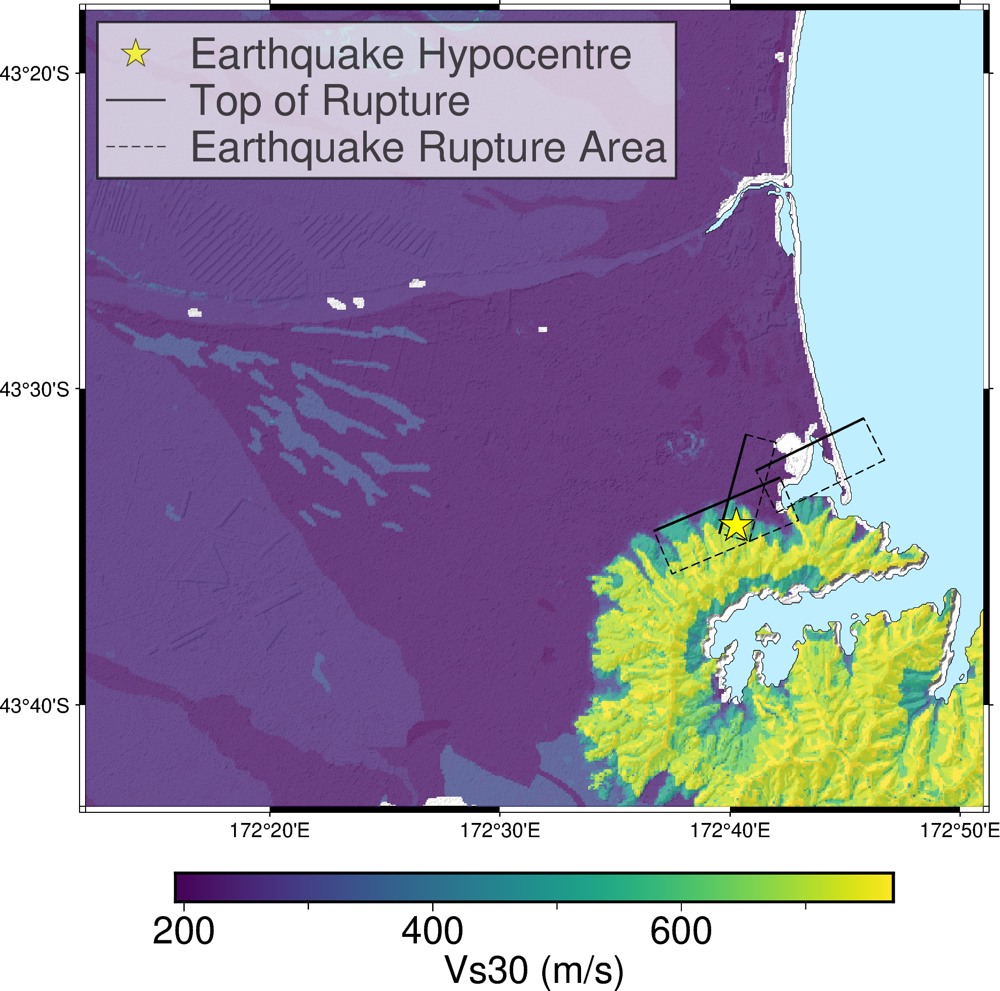

In [15]:
region = chc_extents

grid = pygmt.datasets.load_earth_relief(resolution="01s",region=region)
fig = pygmt.Figure()
pygmt.makecpt(cmap="gray", series=[0, 2000, 20], reverse = True)
fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

pygmt.makecpt(cmap="viridis", series=[150, 750], continuous=True, truncate=[150, 750])
fig.grdimage(grid=vs30_path_100m, cmap= "viridis", projection="M15c", transparency = 20, nan_transparent=True)
fig.coast(shorelines="0.15p,black", water = 'lightblue1', region=region)

fig.coast(shorelines="0.15p,black", water = 'lightblue1', region=region)

# Process each fault plane
corners = corners_dict['3468575']
n_planes = corners.shape[2]   # number of planes is last dimension
for ix in range(n_planes):
        cur_corners = corners[:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
            x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
            y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
            pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
            x=cur_corners[cur_sort_ind[:2], 0],
            y=cur_corners[cur_sort_ind[:2], 1],
            pen="1.0p,black", projection="M15c"
        )

# Plot hyponcenters
for evid in earthquake_source_geom_filt.evid:
    fig.plot(
        x=earthquake_source_geom_filt.hyp_lon,
        y=earthquake_source_geom_filt.hyp_lat,
        style="a0.6c",
        pen="black",
        fill="yellow1",
        projection="M15c",
        )

# Define inset regions
inset_regions = {"inset1": chc_extents}

# dummy labels for legend
fig.plot(x=[0], y=[0], style="a0.5c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")

# legend
with pygmt.config(FONT_ANNOT_PRIMARY="20p", FONT_LABEL="20p"):
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
    fig.colorbar(frame=f'af+lVs30 (m/s)')
fig.show(method='notebook', dpi=300, width=540)
fig.savefig(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\chc_vs30.png', dpi = 300)

### 1.3.2 Z1.0 Map

makecpt [WARNING]: Without inc in -T option, -Z has no effect (ignored)
makecpt [ERROR]: gmt_truncate_cpt: z_high = 1500 larger than highest z (1)


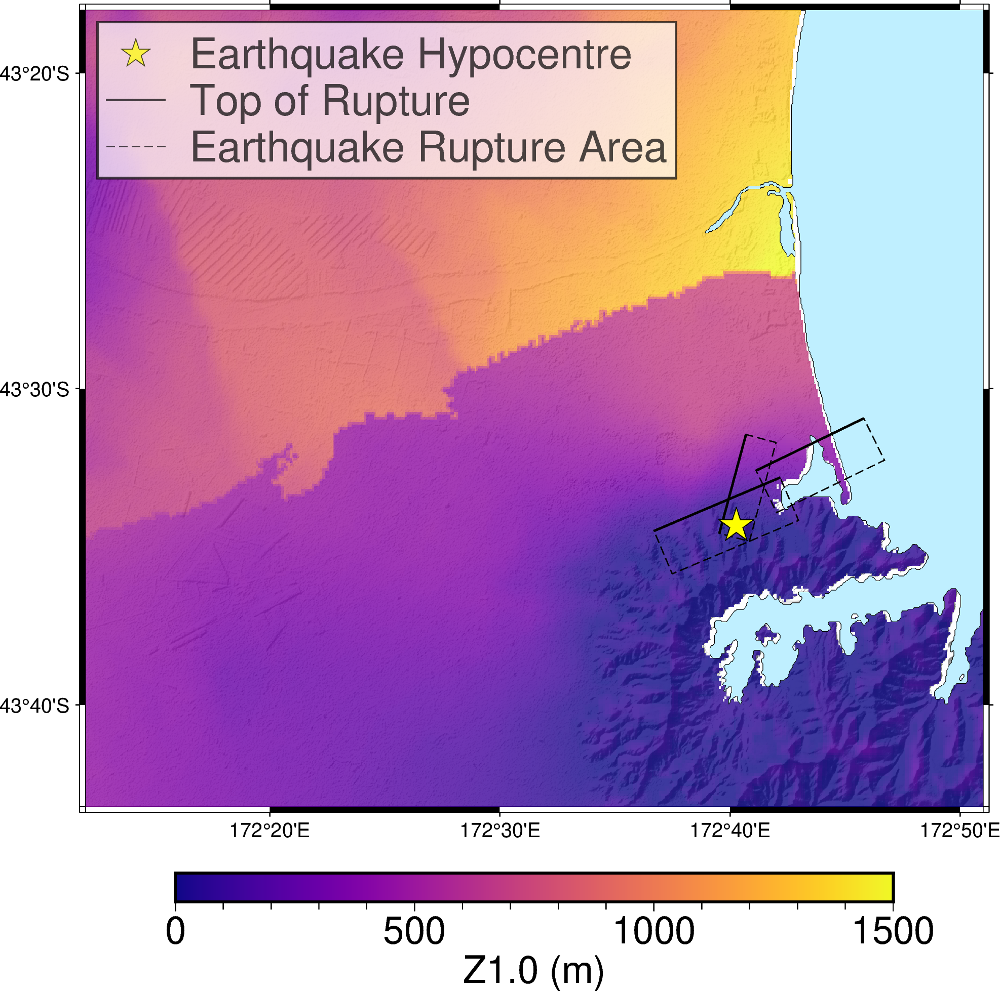

In [16]:
region = chc_extents

grid = pygmt.datasets.load_earth_relief(resolution="01s",region=region)
fig = pygmt.Figure()
pygmt.makecpt(cmap="gray", series=[0, 2000, 20], reverse = True)
fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

pygmt.makecpt(cmap="plasma", series=[0, 1500], continuous=True, truncate=[0, 1500])
fig.grdimage(grid=Z1_path_250m, cmap= "plasma", projection="M15c", transparency = 20, nan_transparent=True)

fig.coast(shorelines="0.15p,black", water = 'lightblue1', region=region)

# Process each fault plane
corners = corners_dict['3468575']
n_planes = corners.shape[2]   # number of planes is last dimension
for ix in range(n_planes):
        cur_corners = corners[:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
            x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
            y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
            pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
            x=cur_corners[cur_sort_ind[:2], 0],
            y=cur_corners[cur_sort_ind[:2], 1],
            pen="1.0p,black", projection="M15c"
        )

# Plot hyponcenters
for evid in earthquake_source_geom_filt.evid:
    fig.plot(
        x=earthquake_source_geom_filt.hyp_lon,
        y=earthquake_source_geom_filt.hyp_lat,
        style="a0.6c",
        pen="black",
        fill="yellow1",
        projection="M15c",
        )

# Define inset regions
inset_regions = {
    "inset1": chc_extents,
    "inset2": kaiwell_extents,
}

# dummy labels for legend
fig.plot(x=[0], y=[0], style="a0.5c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")

# legend
with pygmt.config(FONT_ANNOT_PRIMARY="20p", FONT_LABEL="20p"):
    fig.colorbar(frame=f'af+lZ1.0 (m)')
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
fig.show(method='notebook', dpi=300, width=540)
fig.savefig(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\chc_z1p0.png', dpi = 300)

# 2.0 Empirical reference site correlations

## 2.1 Define reference sites and parameters

In [17]:
ref_site_ids = [
    'DE01270', # rock site/ridge near-fault
    'RHSC', # basin (Good) near-fault
    'DE01475', # basin soil (Good) near-fault
    'HVSC', # basin soil/valley far-fault
    'KPOC', # basin soil (Good) far-fault
]

ref_sites = pd.DataFrame()
ref_sites['sta'] = ref_site_ids
ref_sites['sta_lat'] = [-43.654678, -43.536270, -43.639343, -43.580032, -43.375137]
ref_sites['sta_lon'] = [172.622253, 172.561386, 172.526871, 172.707825, 172.662140]

# get Z1.0, TRI and Vs30 values
with rasterio.open(vs30_path_100m) as src:
    sample_coords = list(zip(ref_sites.sta_lon, ref_sites.sta_lat))
    vs30_values = np.array([val[0] for val in src.sample(sample_coords)])

with rasterio.open(Z1_path_250m) as src:
    sample_coords = list(zip(ref_sites.sta_lon, ref_sites.sta_lat))
    z1_values = np.array([val[0] for val in src.sample(sample_coords)])*1000 # Z1.0 values are in km

with rasterio.open(TRI_path_250m) as src:
    sample_coords = list(zip(ref_sites.sta_lon, ref_sites.sta_lat))
    TRI_values = np.array([val[0] for val in src.sample(sample_coords)])

# load into dataframe
ref_sites['vs30'] = vs30_values
ref_sites['z1p0'] = z1_values
ref_sites['TRI'] = TRI_values

## 2.2 Darfield

In [18]:
ref_sites_dar = ref_sites.copy()
ref_sites_dar['ev_lon'] = gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lon[0]
ref_sites_dar['ev_lat'] = gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lat[0]

# Repi and Razi
Xp = pygmf.LongLatToPolar(ref_sites_dar[['sta_lon','sta_lat']].values, ref_sites_dar[['ev_lon','ev_lat']].values)
ref_sites_dar['r_epi'] = Xp[:,0]
ref_sites_dar['r_azi'] = Xp[:,1]

# compute empirical correlations
ref_site_dar = {}

for ref in tqdm(ref_sites_dar['sta'].tolist(), desc="Processing reference stations"):
    ref = str(ref).strip()

    # copy sites df
    combined_df = sites_dar_SA.copy()

    # get the correct reference-site row
    ref_row = ref_sites_dar.loc[ref_sites_dar['sta'] == ref].iloc[0]

    # build X_site vector
    X_site = ref_row[['r_epi','r_azi','vs30','z1p0','TRI']].values

    # compute dissimilarities
    X_all = sites_dar_SA[['r_epi','r_azi','vs30','z1p0','TRI']].values

    dE = gmscm.getEucDistanceToSite(X_all, X_site)
    dA = np.rad2deg(gmscm.getAngDistanceToSite(X_all, X_site))
    dS = np.abs(sites_dar_SA['vs30'].values - ref_row['vs30'])
    dZ = np.abs(sites_dar_SA['z1p0'].values - ref_row['z1p0'])
    dT = np.abs(sites_dar_SA['TRI'].values - ref_row['TRI'])

    for period in tqdm(pSA_T, desc=f"Periods for {ref}"):
        rhoE     = gmscm.RA26E(period, dE, scm_params_cant)
        rhoEA    = gmscm.RA26EA(period, dE, dA, scm_params_cant)
        rhoEAS   = gmscm.RA26EAS(period, dE, dA, dS, scm_params_cant)
        rhoEASZ  = gmscm.RA26EASZ(period, dE, dA, dS, dZ, scm_params_cant)
        rhoEAST  = gmscm.RA26EAST(period, dE, dA, dS, dT, scm_params_cant)
        rhoEASZT = gmscm.RA26EASZT(period, dE, dA, dS, dZ, dT, scm_params_cant)

        combined_df[f'pE_{period}']     = rhoE
        combined_df[f'pEA_{period}']    = rhoEA
        combined_df[f'pEAS_{period}']   = rhoEAS
        combined_df[f'pEASZ_{period}']  = rhoEASZ
        combined_df[f'pEAST_{period}']  = rhoEAST
        combined_df[f'pEASZT_{period}'] = rhoEASZT

    ref_site_dar[ref] = combined_df

Processing reference stations:   0%|          | 0/5 [00:00<?, ?it/s]

Periods for DE01270:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for RHSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for DE01475:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for HVSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for KPOC:   0%|          | 0/6 [00:00<?, ?it/s]

## 2.3 Christchurch

In [19]:
ref_sites_chc = ref_sites.copy()
ref_sites_chc['ev_lon'] = gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lon[0]
ref_sites_chc['ev_lat'] = gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lat[0]

# Repi and Razi
Xp = pygmf.LongLatToPolar(ref_sites_chc[['sta_lon','sta_lat']].values, ref_sites_chc[['ev_lon','ev_lat']].values)
ref_sites_chc['r_epi'] = Xp[:,0]
ref_sites_chc['r_azi'] = Xp[:,1]

# compute empirical correlations
ref_site_chc = {}

for ref in tqdm(ref_sites_chc['sta'].tolist(), desc="Processing reference stations"):
    ref = str(ref).strip()

    # copy sites df
    combined_df = sites_chc_SA.copy()

    # get the correct reference-site row
    ref_row = ref_sites_chc.loc[ref_sites_chc['sta'] == ref].iloc[0]

    # build X_site vector
    X_site = ref_row[['r_epi','r_azi','vs30','z1p0','TRI']].values

    # compute dissimilarities
    X_all = sites_chc_SA[['r_epi','r_azi','vs30','z1p0','TRI']].values

    dE = gmscm.getEucDistanceToSite(X_all, X_site)
    dA = np.rad2deg(gmscm.getAngDistanceToSite(X_all, X_site))
    dS = np.abs(sites_chc_SA['vs30'].values - ref_row['vs30'])
    dZ = np.abs(sites_chc_SA['z1p0'].values - ref_row['z1p0'])
    dT = np.abs(sites_chc_SA['TRI'].values - ref_row['TRI'])

    for period in tqdm(pSA_T, desc=f"Periods for {ref}"):
        rhoE     = gmscm.RA26E(period, dE, scm_params_cant)
        rhoEA    = gmscm.RA26EA(period, dE, dA, scm_params_cant)
        rhoEAS   = gmscm.RA26EAS(period, dE, dA, dS, scm_params_cant)
        rhoEASZ  = gmscm.RA26EASZ(period, dE, dA, dS, dZ, scm_params_cant)
        rhoEAST  = gmscm.RA26EAST(period, dE, dA, dS, dT, scm_params_cant)
        rhoEASZT = gmscm.RA26EASZT(period, dE, dA, dS, dZ, dT, scm_params_cant)

        combined_df[f'pE_{period}']     = rhoE
        combined_df[f'pEA_{period}']    = rhoEA
        combined_df[f'pEAS_{period}']   = rhoEAS
        combined_df[f'pEASZ_{period}']  = rhoEASZ
        combined_df[f'pEAST_{period}']  = rhoEAST
        combined_df[f'pEASZT_{period}'] = rhoEASZT

    ref_site_chc[ref] = combined_df

Processing reference stations:   0%|          | 0/5 [00:00<?, ?it/s]

Periods for DE01270:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for RHSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for DE01475:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for HVSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for KPOC:   0%|          | 0/6 [00:00<?, ?it/s]

## 2.4 Kaikoura|Wellington

In [20]:
ref_sites_kaiwell = ref_sites.copy()
ref_sites_kaiwell['ev_lon'] = gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lon[0]
ref_sites_kaiwell['ev_lat'] = gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lat[0]

# Repi and Razi
Xp = pygmf.LongLatToPolar(ref_sites_kaiwell[['sta_lon','sta_lat']].values, ref_sites_kaiwell[['ev_lon','ev_lat']].values)
ref_sites_kaiwell['r_epi'] = Xp[:,0]
ref_sites_kaiwell['r_azi'] = Xp[:,1]

# compute empirical correlations
ref_site_kaiwell = {}

for ref in tqdm(ref_sites_kaiwell['sta'].tolist(), desc="Processing reference stations"):
    ref = str(ref).strip()

    # copy sites df
    combined_df = sites_kaiwell_SA.copy()

    # get the correct reference-site row
    ref_row = ref_sites_kaiwell.loc[ref_sites_kaiwell['sta'] == ref].iloc[0]

    # build X_site vector
    X_site = ref_row[['r_epi','r_azi','vs30','z1p0','TRI']].values

    # compute dissimilarities
    X_all = sites_kaiwell_SA[['r_epi','r_azi','vs30','z1p0','TRI']].values

    dE = gmscm.getEucDistanceToSite(X_all, X_site)
    dA = np.rad2deg(gmscm.getAngDistanceToSite(X_all, X_site))
    dS = np.abs(sites_kaiwell_SA['vs30'].values - ref_row['vs30'])
    dZ = np.abs(sites_kaiwell_SA['z1p0'].values - ref_row['z1p0'])
    dT = np.abs(sites_kaiwell_SA['TRI'].values - ref_row['TRI'])

    for period in tqdm(pSA_T, desc=f"Periods for {ref}"):
        rhoE     = gmscm.RA26E(period, dE, scm_params_well)
        rhoEA    = gmscm.RA26EA(period, dE, dA, scm_params_well)
        rhoEAS   = gmscm.RA26EAS(period, dE, dA, dS, scm_params_well)
        rhoEASZ  = gmscm.RA26EASZ(period, dE, dA, dS, dZ, scm_params_well)
        rhoEAST  = gmscm.RA26EAST(period, dE, dA, dS, dT, scm_params_well)
        rhoEASZT = gmscm.RA26EASZT(period, dE, dA, dS, dZ, dT, scm_params_well)

        combined_df[f'pE_{period}']     = rhoE
        combined_df[f'pEA_{period}']    = rhoEA
        combined_df[f'pEAS_{period}']   = rhoEAS
        combined_df[f'pEASZ_{period}']  = rhoEASZ
        combined_df[f'pEAST_{period}']  = rhoEAST
        combined_df[f'pEASZT_{period}'] = rhoEASZT

    ref_site_kaiwell[ref] = combined_df

Processing reference stations:   0%|          | 0/5 [00:00<?, ?it/s]

Periods for DE01270:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for RHSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for DE01475:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for HVSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for KPOC:   0%|          | 0/6 [00:00<?, ?it/s]

## 2.5 Kaikoura

In [21]:
ref_sites_kai = ref_sites.copy()
ref_sites_kai['ev_lon'] = gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lon[0]
ref_sites_kai['ev_lat'] = gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lat[0]

# Repi and Razi
Xp = pygmf.LongLatToPolar(ref_sites_kai[['sta_lon','sta_lat']].values, ref_sites_kai[['ev_lon','ev_lat']].values)
ref_sites_kai['r_epi'] = Xp[:,0]
ref_sites_kai['r_azi'] = Xp[:,1]

# compute empirical correlations
ref_site_kai = {}

for ref in tqdm(ref_sites_kai['sta'].tolist(), desc="Processing reference stations"):
    ref = str(ref).strip()

    # copy sites df
    combined_df = sites_kai_SA.copy()

    # get the correct reference-site row
    ref_row = ref_sites_kai.loc[ref_sites_kai['sta'] == ref].iloc[0]

    # build X_site vector
    X_site = ref_row[['r_epi','r_azi','vs30','z1p0','TRI']].values

    # compute dissimilarities
    X_all = sites_kai_SA[['r_epi','r_azi','vs30','z1p0','TRI']].values

    dE = gmscm.getEucDistanceToSite(X_all, X_site)
    dA = np.rad2deg(gmscm.getAngDistanceToSite(X_all, X_site))
    dS = np.abs(sites_kai_SA['vs30'].values - ref_row['vs30'])
    dZ = np.abs(sites_kai_SA['z1p0'].values - ref_row['z1p0'])
    dT = np.abs(sites_kai_SA['TRI'].values - ref_row['TRI'])

    for period in tqdm(pSA_T, desc=f"Periods for {ref}"):
        rhoE     = gmscm.RA26E(period, dE, scm_params_well)
        rhoEA    = gmscm.RA26EA(period, dE, dA, scm_params_well)
        rhoEAS   = gmscm.RA26EAS(period, dE, dA, dS, scm_params_well)
        rhoEASZ  = gmscm.RA26EASZ(period, dE, dA, dS, dZ, scm_params_well)
        rhoEAST  = gmscm.RA26EAST(period, dE, dA, dS, dT, scm_params_well)
        rhoEASZT = gmscm.RA26EASZT(period, dE, dA, dS, dZ, dT, scm_params_well)

        combined_df[f'pE_{period}']     = rhoE
        combined_df[f'pEA_{period}']    = rhoEA
        combined_df[f'pEAS_{period}']   = rhoEAS
        combined_df[f'pEASZ_{period}']  = rhoEASZ
        combined_df[f'pEAST_{period}']  = rhoEAST
        combined_df[f'pEASZT_{period}'] = rhoEASZT

    ref_site_kai[ref] = combined_df

Processing reference stations:   0%|          | 0/5 [00:00<?, ?it/s]

Periods for DE01270:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for RHSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for DE01475:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for HVSC:   0%|          | 0/6 [00:00<?, ?it/s]

Periods for KPOC:   0%|          | 0/6 [00:00<?, ?it/s]

## 2.6 Plots

### 2.6.1 Darfield

In [ ]:
RA26_model = 'pEASZT'
region = dar_extents

grid = pygmt.datasets.load_earth_relief(resolution="01s",region=region)

for ref in tqdm(ref_site_dar, desc="Processing reference stations"):
    for period in tqdm(pSA_T, desc = 'Processing Periods'):
        T_label = f'{RA26_model}_{period}'

        df_ecorr = ref_site_dar[ref].reset_index()
        df = df_ecorr[["lon", "lat", T_label]].copy()
        ecorr_grid = pygmt.triangulate.regular_grid(data=df,region=region,spacing="0.0005")

        fig = pygmt.Figure()
        pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
        fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

        pygmt.makecpt(cmap="curl", series=[-1, 1])
        fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

        fig.coast(shorelines=True, water = 'lightblue1', region=region)

        # Process each fault plane
        n_planes = corners_dict[dar_evid].shape[2]   # number of planes is last dimension
        for ix in range(n_planes):
            cur_corners = corners_dict[dar_evid][:, :, ix]

            # Draw the outline (close polygon)
            fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
            )

            # Draw the top edge (shallowest two corners by depth)
            cur_sort_ind = np.argsort(cur_corners[:, 2])
            fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
            )

        # plot stations
        fig.plot(x=ref_sites_dar[ref_sites_dar.sta==ref].sta_lon,y=ref_sites_dar[ref_sites_dar.sta==ref].sta_lat,fill='green1',style="t0.25c",pen="black",)

        # plot hypocenter
        fig.plot(x=ref_sites_dar.ev_lon[0],y=ref_sites_dar.ev_lat[0],style="a0.4c",pen="black",fill="yellow1")

        # dummy labels for legend
        fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
        fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
        fig.plot(x=[0], y=[0], style="t0.3c", fill="green1", pen="black", label="Reference site")

        fig.basemap(map_scale="jBR+jMR+o0.2c/0.5c+c-43+w5k")
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p')
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lCorrelation coefficient, ρ({T_label}s)')
        # fig.show(method = 'notebook',dpi=300,width=480)
        fig.savefig(rf'C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\darfield_ref_sites\Darfield_{RA26_model}_{ref}_{T_label}_crop.png', dpi=600)

### 2.6.2 Christchurch

In [ ]:
RA26_model = 'pEAS'
region = chc_extents

grid = pygmt.datasets.load_earth_relief(resolution="01s",region=region)

for ref in tqdm(ref_site_chc, desc="Processing reference stations"):
    for period in tqdm(pSA_T, desc = 'Processing Periods'):
        T_label = f'{RA26_model}_{period}'

        df_ecorr = ref_site_chc[ref].reset_index()
        df = df_ecorr[["lon", "lat", T_label]].copy()
        ecorr_grid = pygmt.triangulate.regular_grid(data=df,region=region,spacing="0.0005")

        fig = pygmt.Figure()
        pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
        fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

        pygmt.makecpt(cmap="curl", series=[-1, 1])
        fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

        fig.coast(shorelines=True, water = 'lightblue1', region=region)

        # Process each fault plane
        n_planes = corners_dict[chc_evid].shape[2]   # number of planes is last dimension
        for ix in range(n_planes):
            cur_corners = corners_dict[chc_evid][:, :, ix]

            # Draw the outline (close polygon)
            fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
            )

            # Draw the top edge (shallowest two corners by depth)
            cur_sort_ind = np.argsort(cur_corners[:, 2])
            fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
            )

        # plot stations
        fig.plot(x=ref_sites_chc[ref_sites_chc.sta==ref].sta_lon,y=ref_sites_chc[ref_sites_chc.sta==ref].sta_lat,fill='green1',style="t0.25c",pen="black",)

        # plot hypocenter
        fig.plot(x=ref_sites_chc.ev_lon[0],y=ref_sites_chc.ev_lat[0],style="a0.4c",pen="black",fill="yellow1")

        # dummy labels for legend
        fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
        fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
        fig.plot(x=[0], y=[0], style="t0.3c", fill="green1", pen="black", label="Reference site")

        fig.basemap(map_scale="jBR+jMR+o0.2c/0.5c+c-43+w5k")
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p')
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lCorrelation coefficient, ρ({T_label}s)')
        # fig.show(method = 'notebook',dpi=300,width=480)
        fig.savefig(rf'C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\christchurch_ref_sites\Christchurch_{RA26_model}_{ref}_{T_label}_crop.png', dpi=600)

# 3.0 Conditional IM: Bradley (2014)

## 3.1 Darfield

CondIM (Bradley14):   0%|          | 0/6 [00:00<?, ?it/s]

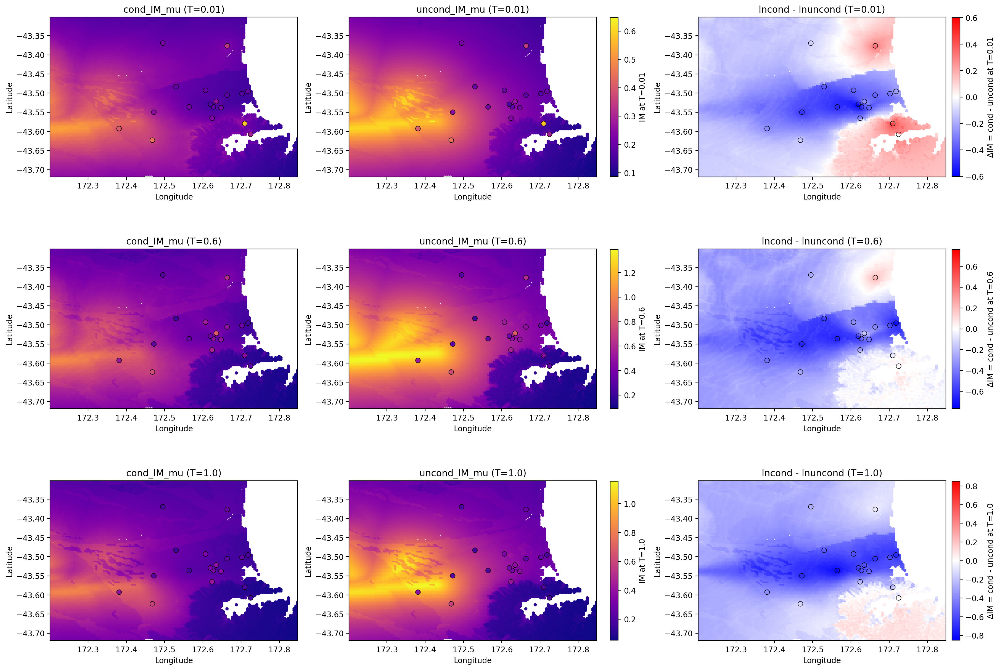

In [19]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

dar_RA26EASZT_B14 = pygmf.condIM_bradley14(
    obs_IM      = dar_obs[cols],
    obs_lnSA_mu = np.log(dar_obssim_SA[cols]),
    obs_lat     = dar_obssim_SA.lat,
    obs_lon     = dar_obssim_SA.lon,

    obs_phi     = dar_obssim_phi[cols],
    obs_tau     = dar_obssim_tau[cols],

    lnSA_mu     = np.log(sites_dar_SA[cols]),
    sites_lat   = sites_dar_SA.lat,
    sites_lon   = sites_dar_SA.lon,
    phi_vals    = sites_dar_SA_phi[cols],
    tau_vals    = sites_dar_SA_tau[cols],

    pSA_T       = pSA_T,
    sites_meta  = np.array(sites_dar_SA[['r_epi','r_azi','vs30','z1p0','TRI']]),
    sites_meta_obs = np.array(dar_obs[['r_epi','r_azi','vs30','z1p0','TRI']]),
    model="RA26EASZT",
    model_kwargs={'parameters': scm_params_cant},
    jitter=1e-10,
    plot_period=[0,2,3],
    progress=True,
)


## 2.2 Christchurch

CondIM (Bradley14):   0%|          | 0/6 [00:00<?, ?it/s]

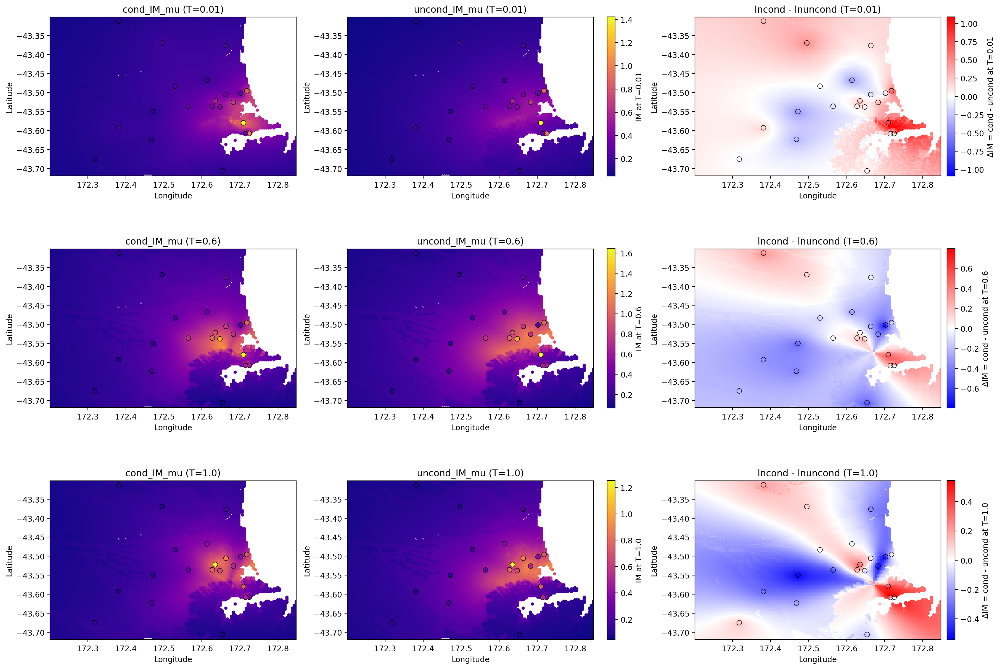

In [29]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

chc_RA26EASZT_B14 = pygmf.condIM_bradley14(
    obs_IM      = chc_obs[cols],
    obs_lnSA_mu = np.log(chc_obssim_SA[cols]),
    obs_lat     = chc_obssim_SA.lat,
    obs_lon     = chc_obssim_SA.lon,

    obs_phi     = chc_obssim_phi[cols],
    obs_tau     = chc_obssim_tau[cols],

    lnSA_mu     = np.log(sites_chc_SA[cols]),
    sites_lat   = sites_chc_SA.lat,
    sites_lon   = sites_chc_SA.lon,
    phi_vals    = sites_chc_SA_phi[cols],
    tau_vals    = sites_chc_SA_tau[cols],

    pSA_T       = pSA_T,
    sites_meta  = np.array(sites_chc_SA[['r_epi','r_azi','vs30','z1p0','TRI']]),
    sites_meta_obs = np.array(chc_obs[['r_epi','r_azi','vs30','z1p0','TRI']]),
    model="RA26EAS",
    model_kwargs={'parameters': scm_params_cant},
    jitter=1e-10,
    plot_period=[0,2,3],
    progress=True,
)

## 2.3 Kaikoura|Wellington

CondIM (Bradley14):   0%|          | 0/6 [00:00<?, ?it/s]

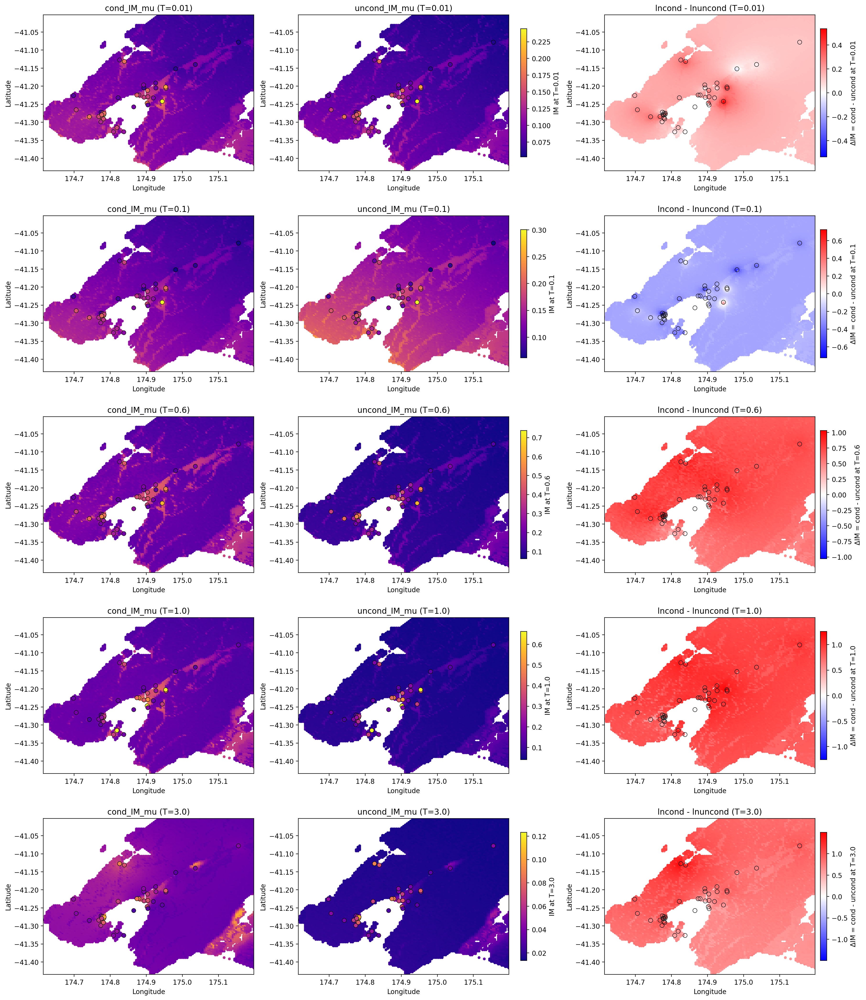

In [20]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

kaiwell_RA26EASZT_B14 = pygmf.condIM_bradley14(
    obs_IM      = kaiwell_obs[cols],
    obs_lnSA_mu = np.log(kaiwell_obssim_SA[cols]),
    obs_lat     = kaiwell_obssim_SA.lat,
    obs_lon     = kaiwell_obssim_SA.lon,

    obs_phi     = kaiwell_obssim_phi[cols],
    obs_tau     = kaiwell_obssim_tau[cols],

    lnSA_mu     = np.log(sites_kaiwell_SA[cols]),
    sites_lat   = sites_kaiwell_SA.lat,
    sites_lon   = sites_kaiwell_SA.lon,
    phi_vals    = sites_kaiwell_SA_phi[cols],
    tau_vals    = sites_kaiwell_SA_tau[cols],

    pSA_T       = pSA_T,
    sites_meta  = np.array(sites_kaiwell_SA[['r_epi','r_azi','vs30','z1p0','TRI']]),
    sites_meta_obs = np.array(kaiwell_obs[['r_epi','r_azi','vs30','z1p0','TRI']]),
    model="RA26EAS",
    model_kwargs={'parameters': scm_params_well},
    jitter=1e-10,
    plot_period=[0,1,2,3,4],
    progress=True,
)

## 2.4 Kaikoura

CondIM (Bradley14):   0%|          | 0/6 [00:00<?, ?it/s]

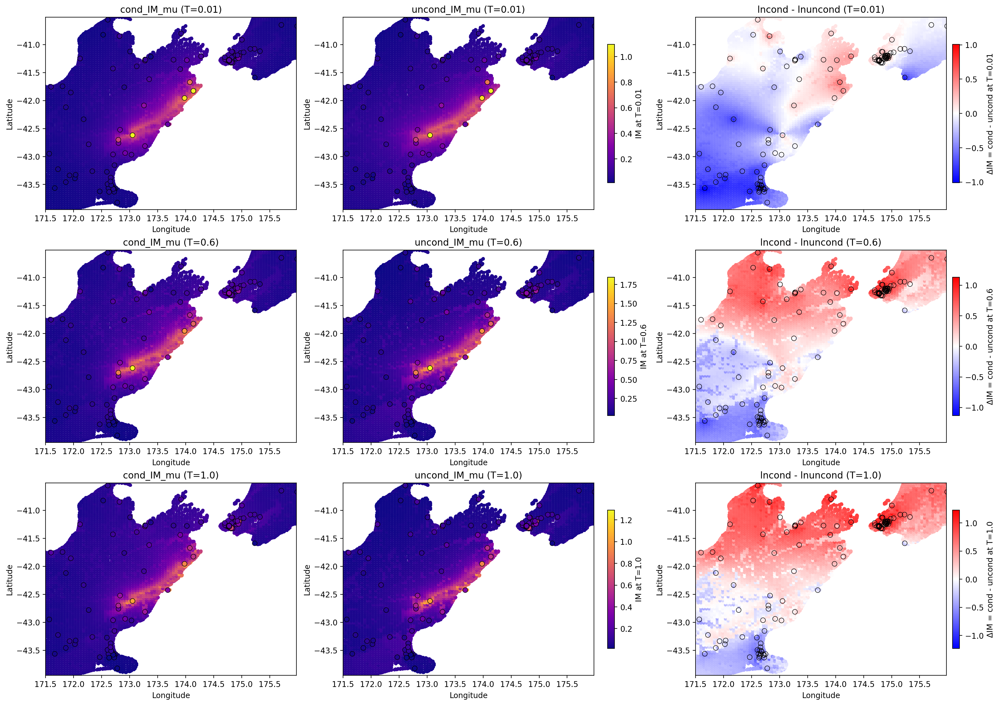

In [30]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

kai_RA26EASZT_B14 = pygmf.condIM_bradley14(
    obs_IM      = kai_obs[cols],
    obs_lnSA_mu = np.log(kai_obssim_SA[cols]),
    obs_lat     = kai_obssim_SA.lat,
    obs_lon     = kai_obssim_SA.lon,

    obs_phi     = kai_obssim_phi[cols],
    obs_tau     = kai_obssim_tau[cols],

    lnSA_mu     = np.log(sites_kai_SA[cols]),
    sites_lat   = sites_kai_SA.lat,
    sites_lon   = sites_kai_SA.lon,
    phi_vals    = sites_kai_SA_phi[cols],
    tau_vals    = sites_kai_SA_tau[cols],

    pSA_T       = pSA_T,
    sites_meta  = np.array(sites_kai_SA[['r_epi','r_azi','vs30','z1p0','TRI']]),
    sites_meta_obs = np.array(kai_obs[['r_epi','r_azi','vs30','z1p0','TRI']]),
    model="RA26EASZT",
    model_kwargs={'parameters': scm_params_nz},
    jitter=1e-10,
    plot_period=[0,2,3],
    progress=True,
)

## 3.5 Plots

### 3.5.1 Darfield

#### 3.5.1.1 Unconditional IMs

In [7]:
region = dar_extents
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=dar_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_dar_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0005")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[dar_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[dar_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lat[0],
            style="a0.3c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = dar_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=dar_obs.lon,
            y=dar_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="14p", FONT_LABEL="14p"):
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_darfield\darfield_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.1.2 Conditional IMs

In [21]:
region = dar_extents
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=dar_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_dar_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = dar_RA26EASZT_B14['cond_IM_mu'][period]
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0005")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[dar_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[dar_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lat[0],
            style="a0.3c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = dar_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=dar_obs.lon,
            y=dar_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="14p", FONT_LABEL="14p"):
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_darfield\darfield_condIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.1.3 lnConditionalIM - lnUnconditional

In [22]:
region = dar_extents
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=dar_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_dar_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = np.log(dar_RA26EASZT_B14['cond_IM_mu'][period]) - np.log(sites_dar_SA[T_label])
    df_SA[T_label] = df_SA[T_label].clip(lower = -1, upper = 1)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="polar", series=[-1, 1])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[dar_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[dar_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==dar_evid].reset_index(drop=True).ev_lat[0],
            style="a0.3c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="polar", series=[-1, 1])
    sa_clipped = np.log(dar_obs[T_label]) - np.log(dar_obssim_SA[T_label])
    sa_clipped =  sa_clipped.clip(lower = -1, upper = 1)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=dar_obs.lon,
            y=dar_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="14p", FONT_LABEL="14p"):
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+llnCondIM - lnUnCondIM ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_darfield\darfield_condIMuncondIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

### 3.5.2 Christchurch

#### 3.5.2.1 Unconditional IMs

In [31]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=chc_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_chc_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0005")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[chc_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[chc_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lat[0],
            style="a0.6c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = chc_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=chc_obs.lon,
            y=chc_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    fig.plot(x=[0], y=[0], style="a0.5c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="20p", FONT_LABEL="20p"):
        fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_christchurch\christchurch_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.2.2 Conditional IMs

In [32]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=chc_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_chc_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = chc_RA26EASZT_B14['cond_IM_mu'][period]
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[chc_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[chc_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lat[0],
            style="a0.5c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = chc_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=chc_obs.lon,
            y=chc_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.5c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    # fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    # fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    # fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="20p", FONT_LABEL="20p"):
        # fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_christchurch\christchurch_condIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.2.3 lnConditionalIM - lnUnconditional

In [30]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=chc_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_chc_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = np.log(chc_RA26EASZT_B14['cond_IM_mu'][period]) - np.log(sites_chc_SA[T_label])
    df_SA[T_label] = df_SA[T_label].clip(lower = -1, upper = 1)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=region,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)

    pygmt.makecpt(cmap="polar", series=[-1, 1])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=region)

    # Process each fault plane
    n_planes = corners_dict[chc_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[chc_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==chc_evid].reset_index(drop=True).ev_lat[0],
            style="a0.6c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="polar", series=[-1, 1])
    sa_clipped = np.log(chc_obs[T_label]) - np.log(chc_obssim_SA[T_label])
    sa_clipped =  sa_clipped.clip(lower = -1, upper = 1)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=chc_obs.lon,
            y=chc_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.5c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    # fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    # fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    # fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    with pygmt.config(FONT_ANNOT_PRIMARY="20p", FONT_LABEL="20p"):
        # fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
        fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+llnCondIM - lnUnCondIM ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_christchurch\christchurch_condIMuncondIM_EAS2_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

### 3.5.3 Kaikoura|Wellington

#### 3.5.3.1 Unconditional IMs

In [ ]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=kaiwell_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kaiwell_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kaiwell_extents,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kaiwell_extents)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kaiwell_extents)

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = kaiwell_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kaiwell_obs.lon,
            y=kaiwell_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )

    # dummy labels for legend
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kaiwell\kaiwell_{T_label}.png", dpi = 600)

#### 3.5.3.2 Conditional IMs

In [16]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=kaiwell_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kaiwell_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = kaiwell_RA26EASZT_B14['cond_IM_mu'][period]
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kaiwell_extents,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kaiwell_extents)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kaiwell_extents)

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = kaiwell_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kaiwell_obs.lon,
            y=kaiwell_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kaiwell\kaiwell_condIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.3.3 lnConditionalIM - lnUnconditional

In [21]:
grid = pygmt.datasets.load_earth_relief(resolution="01s",region=kaiwell_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kaiwell_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = np.log(kaiwell_RA26EASZT_B14['cond_IM_mu'][period]) - np.log(sites_kaiwell_SA[T_label])
    df_SA[T_label] = df_SA[T_label].clip(lower = -1, upper = 1)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kaiwell_extents,spacing="0.0001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kaiwell_extents)

    pygmt.makecpt(cmap="polar", series=[-1, 1])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kaiwell_extents)

    # plot observations
    pygmt.makecpt(cmap="polar", series=[-1, 1])
    sa_clipped = np.log(kaiwell_obs[T_label]) - np.log(kaiwell_obssim_SA[T_label])
    sa_clipped =  sa_clipped.clip(lower = -1, upper = 1)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kaiwell_obs.lon,
            y=kaiwell_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )

    # dummy labels for legend
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kaiwell\kaiwell_condIMuncondIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

### 3.5.4 Kaikoura

#### 3.5.4.1 Unconditional IMs

In [13]:
grid = pygmt.datasets.load_earth_relief(resolution="15s",region=kai_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kai_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kai_extents,spacing="0.001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kai_extents)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kai_extents)

    # Process each fault plane
    n_planes = corners_dict[kai_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[kai_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lat[0],
            style="a0.45c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = kai_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kai_obs.lon,
            y=kai_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )

    # dummy labels for legend
    fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kai\kai_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.4.2 Conditional IMs

In [16]:
grid = pygmt.datasets.load_earth_relief(resolution="15s",region=kai_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kai_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = kai_RA26EASZT_B14['cond_IM_mu'][period]
    df_SA[T_label] = df_SA[T_label].clip(upper=1.5)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kai_extents,spacing="0.001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kai_extents)

    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kai_extents)

    # Process each fault plane
    n_planes = corners_dict[kai_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[kai_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lat[0],
            style="a0.45c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="matter", series=[0, 1.5])
    sa_clipped = kai_obs[T_label].clip(upper=1.5)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kai_obs.lon,
            y=kai_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    # fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kai\kai_condIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

#### 3.5.4.3 lnConditional - lnUnconditional

In [16]:
grid = pygmt.datasets.load_earth_relief(resolution="15s",region=kai_extents)
for period in tqdm(pSA_T, desc = 'Processing Periods'):
    T_label = f'pSA_{period}'

    df_SA = sites_kai_SA[["lon", "lat", T_label]].copy()
    df_SA[T_label] = np.log(kai_RA26EASZT_B14['cond_IM_mu'][period]) - np.log(sites_kai_SA[T_label])
    df_SA[T_label] = df_SA[T_label].clip(lower = -1, upper = 1)
    ecorr_grid = pygmt.triangulate.regular_grid(data=df_SA,region=kai_extents,spacing="0.001")

    fig = pygmt.Figure()
    pygmt.makecpt(cmap="gray", series=[0, 1500, 10], reverse = True)
    fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = kai_extents)

    pygmt.makecpt(cmap="polar", series=[-1, 1])
    fig.grdimage(grid=ecorr_grid, cmap=True, transparency = 20, nan_transparent=True)  # semi-transparent overlay

    fig.coast(shorelines=True, water = 'lightblue1', region=kai_extents)

    # Process each fault plane
    n_planes = corners_dict[kai_evid].shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners_dict[kai_evid][:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                pen="0.5p,black,-", projection="M15c"
        )

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M15c"
        )

    # plot hypocenter
    fig.plot(x=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lon[0],
            y=gm_im_table_50[gm_im_table_50.evid==kai_evid].reset_index(drop=True).ev_lat[0],
            style="a0.35c",
            pen="black",
            fill="yellow1",
            projection="M15c",
            )

    # plot observations
    pygmt.makecpt(cmap="polar", series=[-1, 1])
    sa_clipped = np.log(kai_obs[T_label]) - np.log(kai_obssim_SA[T_label])
    sa_clipped =  sa_clipped.clip(lower = -1, upper = 1)

    # Plot stations as circles colored by residuals
    fig.plot(
            x=kai_obs.lon,
            y=kai_obs.lat,
            style="c0.25c",
            fill=sa_clipped,
            cmap=True,
            pen="black",
            no_clip=True
    )


    # dummy labels for legend
    fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
    fig.plot(x=[0, 0], y=[0, 0], pen="1.0p,black", label="Top of Rupture")
    fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
    fig.plot(x=[0, 0], y=[0, 0], style="c0.25c", label="Observed ground motions")

    # legend
    fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)

    # colorbar
    fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame=f'af+lSpectral Acceleration, SA ({period}s) [g]')
    fig.savefig(rf"C:\Users\LEGION\OneDrive\PhD Documents\Research\Conference_Papers_Posters\PBD2026\figures\condIM_kai\kai_condIMuncondIM_{T_label}.png", dpi = 600)

Processing Periods:   0%|          | 0/6 [00:00<?, ?it/s]

# 4.0 Leave-one-out-conditionalIM (LOO-CIM)

In [15]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

dar_loocim = dar_obs.copy()

for sta in dar_obs['sta']:

        # conditioning set (all but sta)
        dar_obs_filt = dar_obs[dar_obs.sta != sta].reset_index(drop=True)
        dar_obssim_SA_filt  = dar_obssim_SA[dar_obssim_SA.sta != sta].reset_index(drop=True)
        dar_obssim_phi_filt = dar_obssim_phi[dar_obssim_phi.sta != sta].reset_index(drop=True)
        dar_obssim_tau_filt = dar_obssim_tau[dar_obssim_tau.sta != sta].reset_index(drop=True)

        # target (withheld sta)
        dar_obs_sta = dar_obs[dar_obs.sta == sta].reset_index(drop=True)
        dar_obssim_sta     = dar_obssim_SA[dar_obssim_SA.sta == sta].reset_index(drop=True)
        dar_obssim_sta_phi = dar_obssim_phi[dar_obssim_phi.sta == sta].reset_index(drop=True)
        dar_obssim_sta_tau = dar_obssim_tau[dar_obssim_tau.sta == sta].reset_index(drop=True)

        # run the correct model
        dar_cond = pygmf.condIM_bradley14(
            obs_IM      = dar_obs_filt[cols],
            obs_lnSA_mu = np.log(dar_obssim_SA_filt[cols]),
            obs_lat     = dar_obssim_SA_filt.lat,
            obs_lon     = dar_obssim_SA_filt.lon,
            obs_phi     = dar_obssim_phi_filt[cols],
            obs_tau     = dar_obssim_tau_filt[cols],

            lnSA_mu     = np.log(dar_obssim_sta[cols]),
            sites_lat   = dar_obssim_sta.lat,
            sites_lon   = dar_obssim_sta.lon,
            phi_vals    = dar_obssim_sta_phi[cols],
            tau_vals    = dar_obssim_sta_tau[cols],

            pSA_T       = pSA_T,

            # meta: target vs conditioning
            sites_meta      = dar_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values,
            sites_meta_obs  = dar_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values,

            model='RA26E',
            model_kwargs={'parameters': scm_params_cant},
            jitter=1e-10,
            progress=False,
        )

        # compute distance to nearest station
        X_site = dar_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values[0]
        X_all  = dar_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values
        dE = gmscm.getEucDistanceToSite(X_all, X_site)

        # store results
        dar_loocim.loc[dar_loocim.sta == sta, cols] = dar_cond['cond_IM_mu'].values
        dar_loocim.loc[dar_loocim.sta == sta, 'dE_min'] = float(np.min(dE))

## 4.1 Darfield

In [17]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

dar_loocim_dict = {}

for model in ['RA26E', 'RA26EA', 'RA26EAS', 'RA26EASZ', 'RA26EAST', 'RA26EASZT']:

    dar_loocim = dar_obs.copy()   # reset per model

    for sta in dar_obs['sta']:

        # conditioning set (all but sta)
        dar_obs_filt = dar_obs[dar_obs.sta != sta].reset_index(drop=True)
        dar_obssim_SA_filt  = dar_obssim_SA[dar_obssim_SA.sta != sta].reset_index(drop=True)
        dar_obssim_phi_filt = dar_obssim_phi[dar_obssim_phi.sta != sta].reset_index(drop=True)
        dar_obssim_tau_filt = dar_obssim_tau[dar_obssim_tau.sta != sta].reset_index(drop=True)

        # target (withheld sta)
        dar_obs_sta = dar_obs[dar_obs.sta == sta].reset_index(drop=True)
        dar_obssim_sta     = dar_obssim_SA[dar_obssim_SA.sta == sta].reset_index(drop=True)
        dar_obssim_sta_phi = dar_obssim_phi[dar_obssim_phi.sta == sta].reset_index(drop=True)
        dar_obssim_sta_tau = dar_obssim_tau[dar_obssim_tau.sta == sta].reset_index(drop=True)

        # run the correct model
        dar_cond = pygmf.condIM_bradley14(
            obs_IM      = dar_obs_filt[cols],
            obs_lnSA_mu = np.log(dar_obssim_SA_filt[cols]),
            obs_lat     = dar_obssim_SA_filt.lat,
            obs_lon     = dar_obssim_SA_filt.lon,
            obs_phi     = dar_obssim_phi_filt[cols],
            obs_tau     = dar_obssim_tau_filt[cols],

            lnSA_mu     = np.log(dar_obssim_sta[cols]),
            sites_lat   = dar_obssim_sta.lat,
            sites_lon   = dar_obssim_sta.lon,
            phi_vals    = dar_obssim_sta_phi[cols],
            tau_vals    = dar_obssim_sta_tau[cols],

            pSA_T       = pSA_T,

            # meta: target vs conditioning
            sites_meta      = dar_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values,
            sites_meta_obs  = dar_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values,

            model=model,
            model_kwargs={'parameters': scm_params_cant},
            jitter=1e-10,
            progress=False,
        )

        # compute distance to nearest station
        X_site = dar_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values[0]
        X_all  = dar_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values
        dE = gmscm.getEucDistanceToSite(X_all, X_site)

        # store results
        dar_loocim.loc[dar_loocim.sta == sta, cols] = dar_cond['cond_IM_mu'].values
        dar_loocim.loc[dar_loocim.sta == sta, 'dE_min'] = float(np.min(dE))

    dar_loocim_dict[model] = dar_loocim.copy()

## 4.2 Christchurch

In [50]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

chc_loocim_dict = {}

for model in ['RA26E', 'RA26EA', 'RA26EAS', 'RA26EASZ', 'RA26EAST', 'RA26EASZT']:

    chc_loocim = chc_obs.copy()   # reset per model

    for sta in chc_obs['sta']:

        # conditioning set (all but sta)
        chc_obs_filt = chc_obs[chc_obs.sta != sta].reset_index(drop=True)
        chc_obssim_SA_filt  = chc_obssim_SA[chc_obssim_SA.sta != sta].reset_index(drop=True)
        chc_obssim_phi_filt = chc_obssim_phi[chc_obssim_phi.sta != sta].reset_index(drop=True)
        chc_obssim_tau_filt = chc_obssim_tau[chc_obssim_tau.sta != sta].reset_index(drop=True)

        # target (withheld sta)
        chc_obs_sta = chc_obs[chc_obs.sta == sta].reset_index(drop=True)
        chc_obssim_sta     = chc_obssim_SA[chc_obssim_SA.sta == sta].reset_index(drop=True)
        chc_obssim_sta_phi = chc_obssim_phi[chc_obssim_phi.sta == sta].reset_index(drop=True)
        chc_obssim_sta_tau = chc_obssim_tau[chc_obssim_tau.sta == sta].reset_index(drop=True)

        # run the correct model
        chc_cond = pygmf.condIM_bradley14(
            obs_IM      = chc_obs_filt[cols],
            obs_lnSA_mu = np.log(chc_obssim_SA_filt[cols]),
            obs_lat     = chc_obssim_SA_filt.lat,
            obs_lon     = chc_obssim_SA_filt.lon,
            obs_phi     = chc_obssim_phi_filt[cols],
            obs_tau     = chc_obssim_tau_filt[cols],

            # target must use obssim (NOT chc_obs)
            lnSA_mu     = np.log(chc_obssim_sta[cols]),
            sites_lat   = chc_obssim_sta.lat,
            sites_lon   = chc_obssim_sta.lon,
            phi_vals    = chc_obssim_sta_phi[cols],
            tau_vals    = chc_obssim_sta_tau[cols],

            pSA_T       = pSA_T,

            # meta: target vs conditioning
            sites_meta      = chc_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values,
            sites_meta_obs  = chc_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values,

            model=model,
            model_kwargs={'parameters': scm_params_cant},
            jitter=1e-10,
            progress=False,
        )

        # compute distance to nearest conditioning station (feature space)
        X_site = chc_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values[0]
        X_all  = chc_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values
        dE = gmscm.getEucDistanceToSite(X_all, X_site)

        # store results
        chc_loocim.loc[chc_loocim.sta == sta, cols] = chc_cond['cond_IM_mu'].values
        chc_loocim.loc[chc_loocim.sta == sta, 'dE_min'] = float(np.min(dE))

    chc_loocim_dict[model] = chc_loocim.copy()

## 4.3 Kaikoura|Wellington

In [52]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

kaiwell_loocim = kaiwell_obs.copy()
kaiwell_loocim_dict = {}

for model in ['RA26E', 'RA26EA', 'RA26EAS', 'RA26EASZ', 'RA26EAST', 'RA26EASZT']:

    kaiwell_loocim = kaiwell_obs.copy()   # reset per model

    for sta in kaiwell_obs['sta']:

        # conditioning set (all but sta)
        kaiwell_obs_filt = kaiwell_obs[kaiwell_obs.sta != sta].reset_index(drop=True)
        kaiwell_obssim_SA_filt  = kaiwell_obssim_SA[kaiwell_obssim_SA.sta != sta].reset_index(drop=True)
        kaiwell_obssim_phi_filt = kaiwell_obssim_phi[kaiwell_obssim_phi.sta != sta].reset_index(drop=True)
        kaiwell_obssim_tau_filt = kaiwell_obssim_tau[kaiwell_obssim_tau.sta != sta].reset_index(drop=True)

        # target (withheld sta)
        kaiwell_obs_sta = kaiwell_obs[kaiwell_obs.sta == sta].reset_index(drop=True)
        kaiwell_obssim_sta     = kaiwell_obssim_SA[kaiwell_obssim_SA.sta == sta].reset_index(drop=True)
        kaiwell_obssim_sta_phi = kaiwell_obssim_phi[kaiwell_obssim_phi.sta == sta].reset_index(drop=True)
        kaiwell_obssim_sta_tau = kaiwell_obssim_tau[kaiwell_obssim_tau.sta == sta].reset_index(drop=True)

        # run the correct model
        kaiwell_cond = pygmf.condIM_bradley14(
            obs_IM      = kaiwell_obs_filt[cols],
            obs_lnSA_mu = np.log(kaiwell_obssim_SA_filt[cols]),
            obs_lat     = kaiwell_obssim_SA_filt.lat,
            obs_lon     = kaiwell_obssim_SA_filt.lon,
            obs_phi     = kaiwell_obssim_phi_filt[cols],
            obs_tau     = kaiwell_obssim_tau_filt[cols],

            # target must use obssim (not obs)
            lnSA_mu     = np.log(kaiwell_obssim_sta[cols]),
            sites_lat   = kaiwell_obssim_sta.lat,
            sites_lon   = kaiwell_obssim_sta.lon,
            phi_vals    = kaiwell_obssim_sta_phi[cols],
            tau_vals    = kaiwell_obssim_sta_tau[cols],

            pSA_T       = pSA_T,

            # meta: target vs conditioning
            sites_meta      = kaiwell_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values,
            sites_meta_obs  = kaiwell_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values,

            model=model,
            model_kwargs={'parameters': scm_params_cant},
            jitter=1e-10,
            progress=False,
        )

        # compute distance to nearest conditioning station (feature space)
        X_site = kaiwell_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values[0]
        X_all  = kaiwell_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values
        dE = gmscm.getEucDistanceToSite(X_all, X_site)

        # store results
        kaiwell_loocim.loc[kaiwell_loocim.sta == sta, cols] = kaiwell_cond['cond_IM_mu'].values
        kaiwell_loocim.loc[kaiwell_loocim.sta == sta, 'dE_min'] = float(np.min(dE))

    kaiwell_loocim_dict[model] = kaiwell_loocim.copy()

## 4.4 Kaikoura

In [53]:
cols = ['pSA_0.01','pSA_0.1','pSA_0.6','pSA_1.0','pSA_3.0','pSA_6.0']
pSA_T = [0.01, 0.1, 0.6, 1.0, 3.0, 6.0]

kai_loocim = kai_obs.copy()
kai_loocim_dict = {}

for model in ['RA26E', 'RA26EA', 'RA26EAS', 'RA26EASZ', 'RA26EAST', 'RA26EASZT']:

    kai_loocim = kai_obs.copy()   # reset per model

    for sta in kai_obs['sta']:

        # conditioning set (all but sta)
        kai_obs_filt = kai_obs[kai_obs.sta != sta].reset_index(drop=True)
        kai_obssim_SA_filt  = kai_obssim_SA[kai_obssim_SA.sta != sta].reset_index(drop=True)
        kai_obssim_phi_filt = kai_obssim_phi[kai_obssim_phi.sta != sta].reset_index(drop=True)
        kai_obssim_tau_filt = kai_obssim_tau[kai_obssim_tau.sta != sta].reset_index(drop=True)

        # target (withheld sta)
        kai_obs_sta = kai_obs[kai_obs.sta == sta].reset_index(drop=True)
        kai_obssim_sta     = kai_obssim_SA[kai_obssim_SA.sta == sta].reset_index(drop=True)
        kai_obssim_sta_phi = kai_obssim_phi[kai_obssim_phi.sta == sta].reset_index(drop=True)
        kai_obssim_sta_tau = kai_obssim_tau[kai_obssim_tau.sta == sta].reset_index(drop=True)

        # run the correct model
        kai_cond = pygmf.condIM_bradley14(
            obs_IM      = kai_obs_filt[cols],
            obs_lnSA_mu = np.log(kai_obssim_SA_filt[cols]),
            obs_lat     = kai_obssim_SA_filt.lat,
            obs_lon     = kai_obssim_SA_filt.lon,
            obs_phi     = kai_obssim_phi_filt[cols],
            obs_tau     = kai_obssim_tau_filt[cols],

            # target must use obssim (not obs)
            lnSA_mu     = np.log(kai_obssim_sta[cols]),
            sites_lat   = kai_obssim_sta.lat,
            sites_lon   = kai_obssim_sta.lon,
            phi_vals    = kai_obssim_sta_phi[cols],
            tau_vals    = kai_obssim_sta_tau[cols],

            pSA_T       = pSA_T,

            # meta: target vs conditioning
            sites_meta      = kai_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values,
            sites_meta_obs  = kai_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values,

            model=model,
            model_kwargs={'parameters': scm_params_nz},
            jitter=1e-10,
            progress=False,
        )

        # compute distance to nearest conditioning station (feature space)
        X_site = kai_obs_sta[['r_epi','r_azi','vs30','z1p0','TRI']].values[0]
        X_all  = kai_obs_filt[['r_epi','r_azi','vs30','z1p0','TRI']].values
        dE = gmscm.getEucDistanceToSite(X_all, X_site)

        # store results
        kai_loocim.loc[kai_loocim.sta == sta, cols] = kai_cond['cond_IM_mu'].values
        kai_loocim.loc[kai_loocim.sta == sta, 'dE_min'] = float(np.min(dE))

    kai_loocim_dict[model] = kai_loocim.copy()

## 4.5 Plot Results

In [19]:
def _residual_matrix(dar_obs, dar_pred, cols):
    """
    Return residuals matrix shape (N, nP): ln(IM_obs) - ln(IM_cond)
    with finite masking.
    """
    obs = dar_obs[cols].to_numpy(dtype=float)
    pred = dar_pred[cols].to_numpy(dtype=float)

    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.log(obs) - np.log(pred)

    # mask out anything non-finite (or non-positive inputs)
    r[~np.isfinite(r)] = np.nan
    return r

def _mean_and_ci(r, z=1.96):
    """
    r: (N, nP) residuals
    returns per-period mean and 95% CI on mean (mean ± z*SEM)
    """
    n = np.sum(np.isfinite(r), axis=0).astype(float)
    mu = np.nanmean(r, axis=0)
    sd = np.nanstd(r, axis=0, ddof=1)
    sem = sd / np.sqrt(np.maximum(n, 1.0))
    lo = mu - z * sem
    hi = mu + z * sem
    return mu, lo, hi

### 4.5.1 Darfield

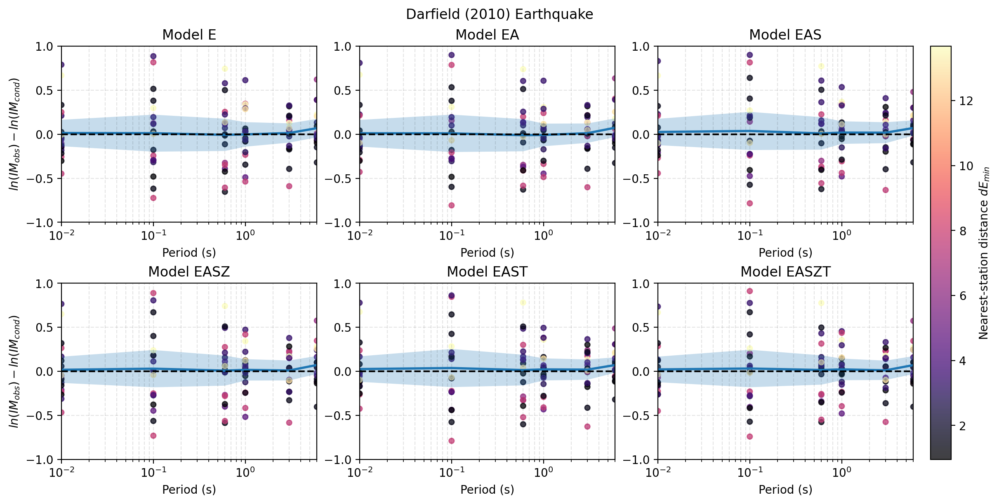

In [49]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(dar_obs)
x = np.array(pSA_T, dtype=float)
periods_tiled = np.tile(x, N)

panels = [
    ("RA26E",    (0,0), "Model E"),
    ("RA26EA",   (0,1), "Model EA"),
    ("RA26EAS",  (0,2), "Model EAS"),
    ("RA26EASZ", (1,0), "Model EASZ"),
    ("RA26EAST", (1,1), "Model EAST"),
    ("RA26EASZT",(1,2), "Model EASZT"),
]

sc_for_cbar = None

for key, (i,j), title in panels:

    # scatter points
    y_flat = _residual_matrix(dar_obs, dar_loocim_dict[key], cols).reshape(-1)
    cvals  = np.repeat(dar_loocim_dict[key]['dE_min'].to_numpy(dtype=float), len(x))

    sc = ax[i,j].scatter(
        periods_tiled,
        y_flat,
        c=cvals,
        cmap='magma',
        s=20,
        alpha=0.75
    )
    if sc_for_cbar is None:
        sc_for_cbar = sc

    # mean + 95% CI band (on the mean)
    r = _residual_matrix(dar_obs, dar_loocim_dict[key], cols)   # (N, nP)
    mu, lo, hi = _mean_and_ci(r, z=1.96)

    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0)   # confidence band
    ax[i,j].plot(x, mu, linewidth=2)                           # mean line

    # cosmetics (your original)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0, 0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

cbar = fig.colorbar(sc_for_cbar, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Darfield (2010) Earthquake')
plt.show()

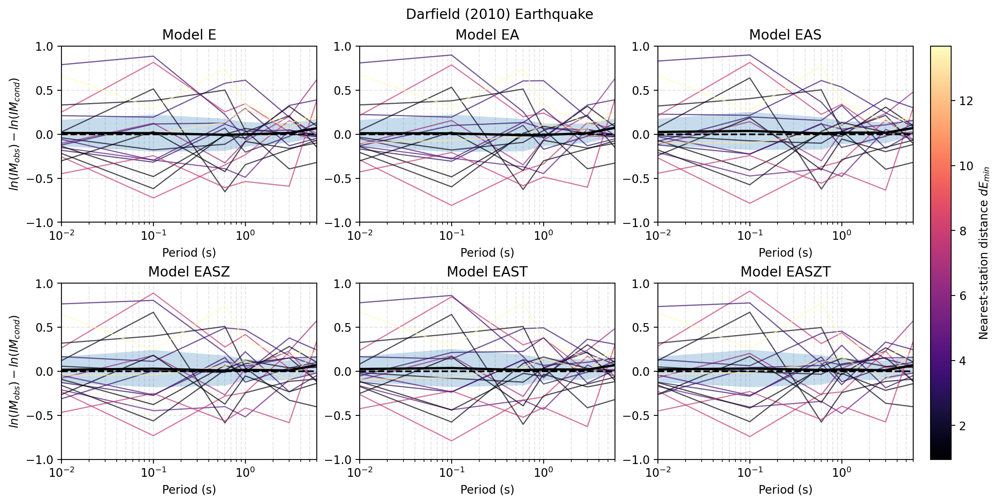

In [20]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(dar_obs)
x = np.array(pSA_T, dtype=float)

panels = [
    ("RA26E",    (0,0), "Model E"),
    ("RA26EA",   (0,1), "Model EA"),
    ("RA26EAS",  (0,2), "Model EAS"),
    ("RA26EASZ", (1,0), "Model EASZ"),
    ("RA26EAST", (1,1), "Model EAST"),
    ("RA26EASZT",(1,2), "Model EASZT"),
]

# Use a consistent color scale across all subplots
dE_all = dar_loocim_dict["RA26E"]["dE_min"].to_numpy(dtype=float)
norm = mpl.colors.Normalize(vmin=np.nanmin(dE_all), vmax=np.nanmax(dE_all))
cmap = mpl.colormaps.get_cmap("magma")

for key, (i,j), title in panels:

    # residuals matrix (N, nP): ln(IM_obs) - ln(IM_cond)
    r = _residual_matrix(dar_obs, dar_loocim_dict[key], cols)  # (N, nP)
    dE = dar_loocim_dict[key]["dE_min"].to_numpy(dtype=float)  # (N,)

    # colored connecting lines (one per station)
    for k in range(N):
        y = r[k, :]
        m = np.isfinite(y)
        if np.sum(m) < 2:
            continue
        ax[i,j].plot(x[m], y[m], color=cmap(norm(dE[k])), linewidth=1.0, alpha=0.7)

    # mean + 95% CI band (on the mean)
    mu, lo, hi = _mean_and_ci(r, z=1.96)
    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0)
    ax[i,j].plot(x, mu, color="k", linewidth=2.0)

    # cosmetics (same as yours)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0, 0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

# colorbar (needs a mappable)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Darfield (2010) Earthquake')
plt.show()

### 4.5.2 Christchurch

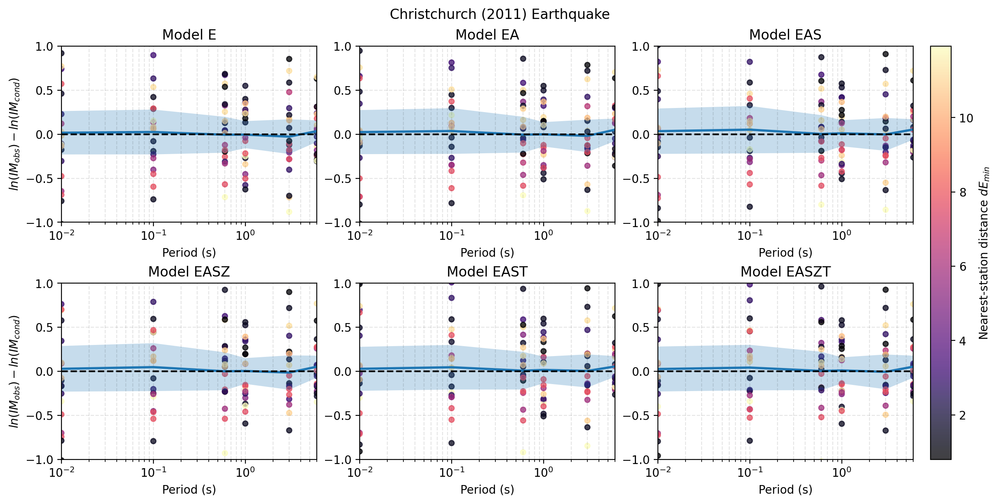

In [58]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(chc_obs)
periods_tiled = np.tile(pSA_T, N)
x = np.array(pSA_T, dtype=float)

panels = [
    ('RA26E',    (0,0), "Model E"),
    ('RA26EA',   (0,1), "Model EA"),
    ('RA26EAS',  (0,2), "Model EAS"),
    ('RA26EASZ', (1,0), "Model EASZ"),
    ('RA26EAST', (1,1), "Model EAST"),
    ('RA26EASZT',(1,2), "Model EASZT"),
]

sc = None

for key, (i,j), title in panels:

    # scatter
    r = _residual_matrix(chc_obs, chc_loocim_dict[key], cols)  # (N, nP)
    y_flat = r.reshape(-1)

    cvals = np.repeat(chc_loocim_dict[key]['dE_min'].to_numpy(dtype=float), len(pSA_T))

    sc_i = ax[i,j].scatter(
        periods_tiled,
        y_flat,
        c=cvals,
        cmap='magma',
        s=20,
        alpha=0.75
    )
    if sc is None:
        sc = sc_i

    # mean + 95% CI band on the mean
    mu, lo, hi = _mean_and_ci(r, z=1.96)
    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0)
    ax[i,j].plot(x, mu, linewidth=2)

    # cosmetics (your original)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0,0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

cbar = fig.colorbar(sc, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Christchurch (2011) Earthquake')
plt.show()

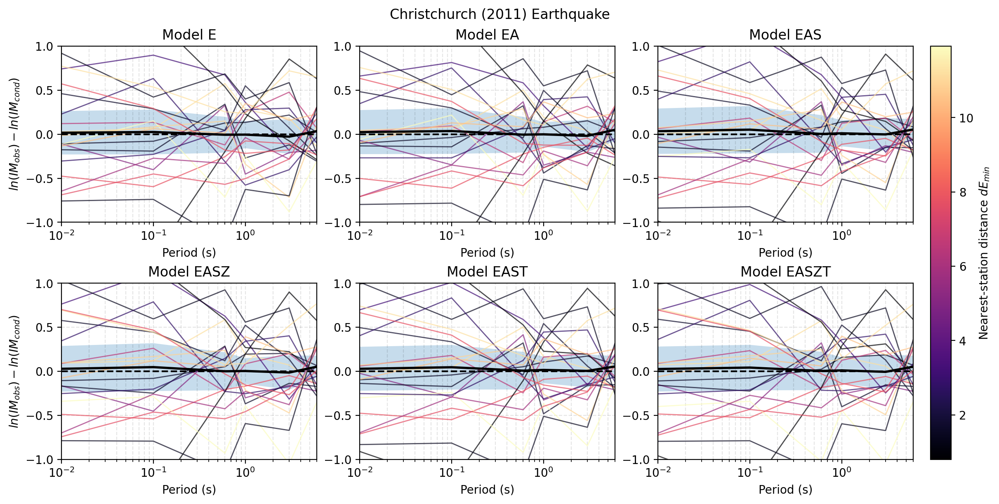

In [64]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(chc_obs)
x = np.array(pSA_T, dtype=float)

panels = [
    ('RA26E',    (0,0), "Model E"),
    ('RA26EA',   (0,1), "Model EA"),
    ('RA26EAS',  (0,2), "Model EAS"),
    ('RA26EASZ', (1,0), "Model EASZ"),
    ('RA26EAST', (1,1), "Model EAST"),
    ('RA26EASZT',(1,2), "Model EASZT"),
]

# consistent color scale across subplots
dE_all = chc_loocim_dict['RA26E']['dE_min'].to_numpy(dtype=float)
norm = mpl.colors.Normalize(vmin=np.nanmin(dE_all), vmax=np.nanmax(dE_all))
cmap = mpl.colormaps["magma"]

for key, (i,j), title in panels:

    # residuals (N, nP)
    r = _residual_matrix(chc_obs, chc_loocim_dict[key], cols)
    dE = chc_loocim_dict[key]['dE_min'].to_numpy(dtype=float)

    # colored connecting lines (one per station)
    for k in range(N):
        y = r[k, :]
        m = np.isfinite(y)
        if np.sum(m) < 2:
            continue
        ax[i,j].plot(x[m], y[m], color=cmap(norm(dE[k])), linewidth=1.0, alpha=0.7)

    # mean + 95% CI band on the mean
    mu, lo, hi = _mean_and_ci(r, z=1.96)
    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0)
    ax[i,j].plot(x, mu, color="k", linewidth=2)

    # cosmetics (your original)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0,0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

# colorbar (needs a mappable)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Christchurch (2011) Earthquake')
plt.show()

### 4.5.3 Kaikoura|Wellington

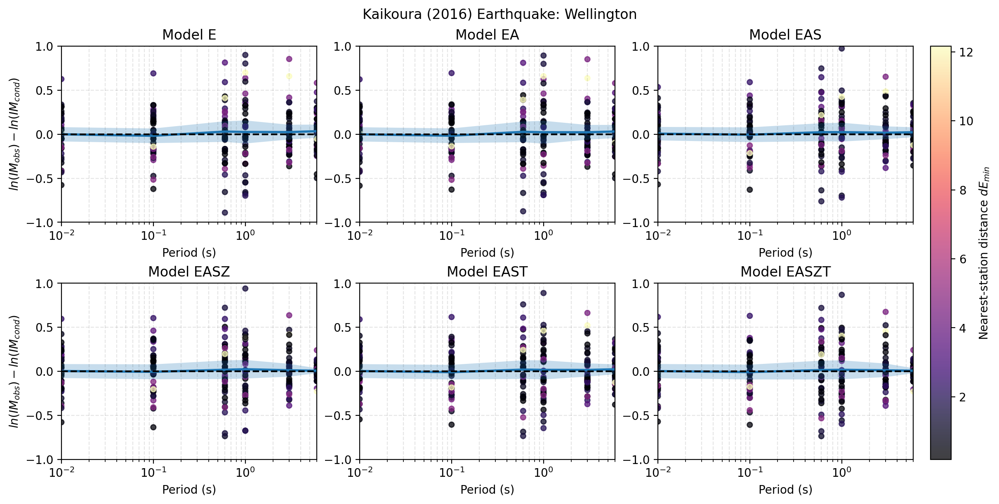

In [59]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(kaiwell_obs)
x = np.array(pSA_T, dtype=float)
periods_tiled = np.tile(x, N)

panels = [
    ("RA26E",    (0,0), "Model E"),
    ("RA26EA",   (0,1), "Model EA"),
    ("RA26EAS",  (0,2), "Model EAS"),
    ("RA26EASZ", (1,0), "Model EASZ"),
    ("RA26EAST", (1,1), "Model EAST"),
    ("RA26EASZT",(1,2), "Model EASZT"),
]

sc = None

for key, (i,j), title in panels:

    # residuals (N, nP)
    r = _residual_matrix(kaiwell_obs, kaiwell_loocim_dict[key], cols)

    # scatter
    y_flat = r.reshape(-1)
    cvals  = np.repeat(kaiwell_loocim_dict[key]['dE_min'].to_numpy(dtype=float), len(x))

    sc_i = ax[i,j].scatter(
        periods_tiled,
        y_flat,
        c=cvals,
        cmap='magma',
        s=20,
        alpha=0.75
    )
    if sc is None:
        sc = sc_i

    # mean + CI band
    mu, lo, hi = _mean_and_ci(r, z=1.96)
    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0)
    ax[i,j].plot(x, mu, linewidth=2)

    # cosmetics (your original)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0,0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

cbar = fig.colorbar(sc, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Kaikoura (2016) Earthquake: Wellington')
plt.show()

### 4.5.4 Kaikoura

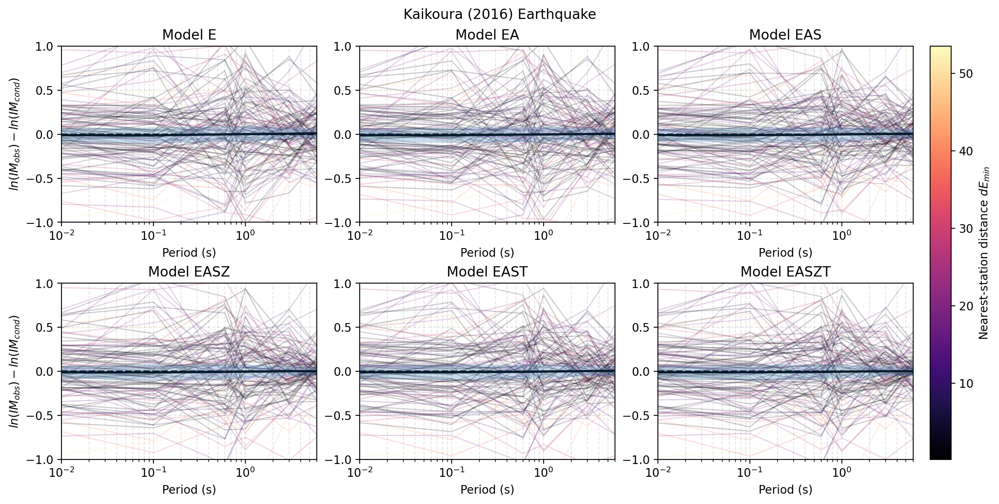

In [69]:
fig, ax = plt.subplots(2,3, figsize=(12,6), dpi=200, constrained_layout=True)

N = len(kai_obs)
x = np.array(pSA_T, dtype=float)

panels = [
    ("RA26E",    (0,0), "Model E"),
    ("RA26EA",   (0,1), "Model EA"),
    ("RA26EAS",  (0,2), "Model EAS"),
    ("RA26EASZ", (1,0), "Model EASZ"),
    ("RA26EAST", (1,1), "Model EAST"),
    ("RA26EASZT",(1,2), "Model EASZT"),
]

# consistent color scale across subplots
dE_all = kai_loocim_dict["RA26E"]["dE_min"].to_numpy(dtype=float)
norm = mpl.colors.Normalize(vmin=np.nanmin(dE_all), vmax=np.nanmax(dE_all))
cmap = mpl.colormaps["magma"]

for key, (i,j), title in panels:

    # residuals (N, nP)
    r  = _residual_matrix(kai_obs, kai_loocim_dict[key], cols)
    dE = kai_loocim_dict[key]["dE_min"].to_numpy(dtype=float)

    # colored connecting lines (one per station)
    for k in range(N):
        y = r[k, :]
        m = np.isfinite(y)
        if np.sum(m) < 2:
            continue
        ax[i,j].plot(x[m], y[m], color=cmap(norm(dE[k])), linewidth=1.0, alpha=0.2)

    # mean + 95% CI band (on the mean)
    mu, lo, hi = _mean_and_ci(r, z=1.96)
    ax[i,j].fill_between(x, lo, hi, alpha=0.25, linewidth=0, zorder = 100)
    ax[i,j].plot(x, mu, color="k", linewidth=2)

    # cosmetics (your original)
    ax[i,j].set_xlim(np.min(x), np.max(x))
    ax[i,j].plot([np.min(x), np.max(x)], [0,0], '--k')
    ax[i,j].grid(which='both', linestyle='--', color='k', alpha=0.1)
    ax[i,j].set_ylim(-1.0, 1.0)
    ax[i,j].set_xscale('log')
    ax[i,j].set_xlabel("Period (s)")
    ax[i,j].set_title(title)

ax[0,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")
ax[1,0].set_ylabel(r"$ln(IM_{obs}) - ln(IM_{cond})$")

# colorbar (needs a mappable)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax.ravel().tolist(), pad=0.02)
cbar.set_label(r"Nearest-station distance $dE_{min}$")

plt.suptitle('Kaikoura (2016) Earthquake')
plt.show()